# Augment rare cell types

A reference with few cells of some types trains a model that under-calls them.
`augment_data()` balances the classes: types below `norm_number` cells get simulated
cells, and with `prune=True` larger types are down-sampled. The simulated cells draw
molecules from the pooled counts of their type. This tutorial follows the R article
[How to augment data using viewmastR](https://furlan-lab.github.io/viewmastR/articles/Augment.html).

| Role | Dataset |
|---|---|
| Reference | BoneMarrowMap healthy bone marrow atlas (Zeng et al. 2025), 263,159 cells, finest labels `CellType` (55 types) |
| Query | T-cell-depleted bone marrow, multiome RNA, 8,627 cells with the authors' labels and UMAP (Persad et al. 2023; the file the [Mellon](https://github.com/settylab/Mellon) tutorial uses) |

The steps below are the ones `tutorial_data.bonemarrowmap_augmented()` runs for tutorial 01 and the README figure,
with the same seeds, so both tutorials use the same reference.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import viewmastr as vm
import celltype_colors as cc
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
col = "CellType"
ref = td.bonemarrowmap_reference()  # 3.7 GB download on first use; about 12 GB in memory
print(ref.obs[col].value_counts().to_string())

CellType
CD4 Naive                      24063
CD14 Mono                      23957
HSC                            12641
CD4 Central Memory             12152
Early GMP                      11432
Cycling Progenitor              9366
CD8 Naive                       8502
CD8 Effector Memory 2           8486
Pro-Erythroblast                7390
CD4 Effector Memory             7361
CFU-E                           7318
Mature B                        6730
LMPP                            6718
BFU-E                           6554
MPP-MkEry                       5771
NK                              5771
MPP-MyLy                        5591
Basophilic Erythroblast         5253
Early ProMono                   5086
Polychromatic Erythroblast      5061
CD16 Mono                       4996
Pro-B VDJ                       4909
MEP                             4856
GMP-Mono                        4557
pDC                             4269
Orthochromatic Erythroblast     3734
cDC2                         

## Hold out real cells for an honest test

Keep 20 % of the real cells of every type aside (at most 1,000 per type). Both models
below train on the other cells; only the second one is augmented. The held-out cells are
never simulated.

In [2]:
train, held = td.bonemarrowmap_split(ref, col, holdout=0.2, max_held=1000, seed=0)
del ref
print(train.shape, held.shape)

(227584, 34009) (35575, 34009)


## Augment to 3,000 cells per type

Types below 3,000 cells get simulated cells; with `prune=True` larger types are randomly
down-sampled to 3,000. The real cells that remain are the "not augmented" reference below,
so the two models differ only by the simulated cells.

In [3]:
aug = vm.augment_data(train, col, norm_number=3000, prune=True, seed=0)
aug.obs["simulated"] = aug.obs_names.str.startswith("stimcell_")
real = aug[~aug.obs["simulated"].to_numpy()].copy()
n = pd.DataFrame({"real cells": train.obs[col].value_counts(),
                  "kept": real.obs[col].value_counts(),
                  "simulated": aug.obs.loc[aug.obs["simulated"], col].value_counts(),
                  "after": aug.obs[col].value_counts()}).fillna(0).astype(int)
print(n.sort_values("real cells").to_string())
rare = n.index[n["simulated"] > 0]
del train

                             real cells  kept  simulated  after
CellType                                                       
Megakaryocyte                        44    44       2956   3000
Stromal                             171   171       2829   3000
NK Proliferating                    172   172       2828   3000
cDC1                                296   296       2704   3000
MLP-II                              405   405       2595   3000
ASDC                                442   442       2558   3000
T Proliferating                     464   464       2536   3000
Pre-ProB                            630   630       2370   3000
Pro-B Cycling                       895   895       2105   3000
Small Pre-B                         971   971       2029   3000
MLP                                 994   994       2006   3000
CLP                                1020  1020       1980   3000
CD8 Tissue Resident Memory         1183  1183       1817   3000
CD4 Regulatory                     1231 

The simulated cells should sit with the real cells of their type in an embedding. This
check uses 300 cells per type. Here they land at the edge of their type's real cells,
often as a tight group: they share the pooled profile of their type, so they vary less
than real cells.

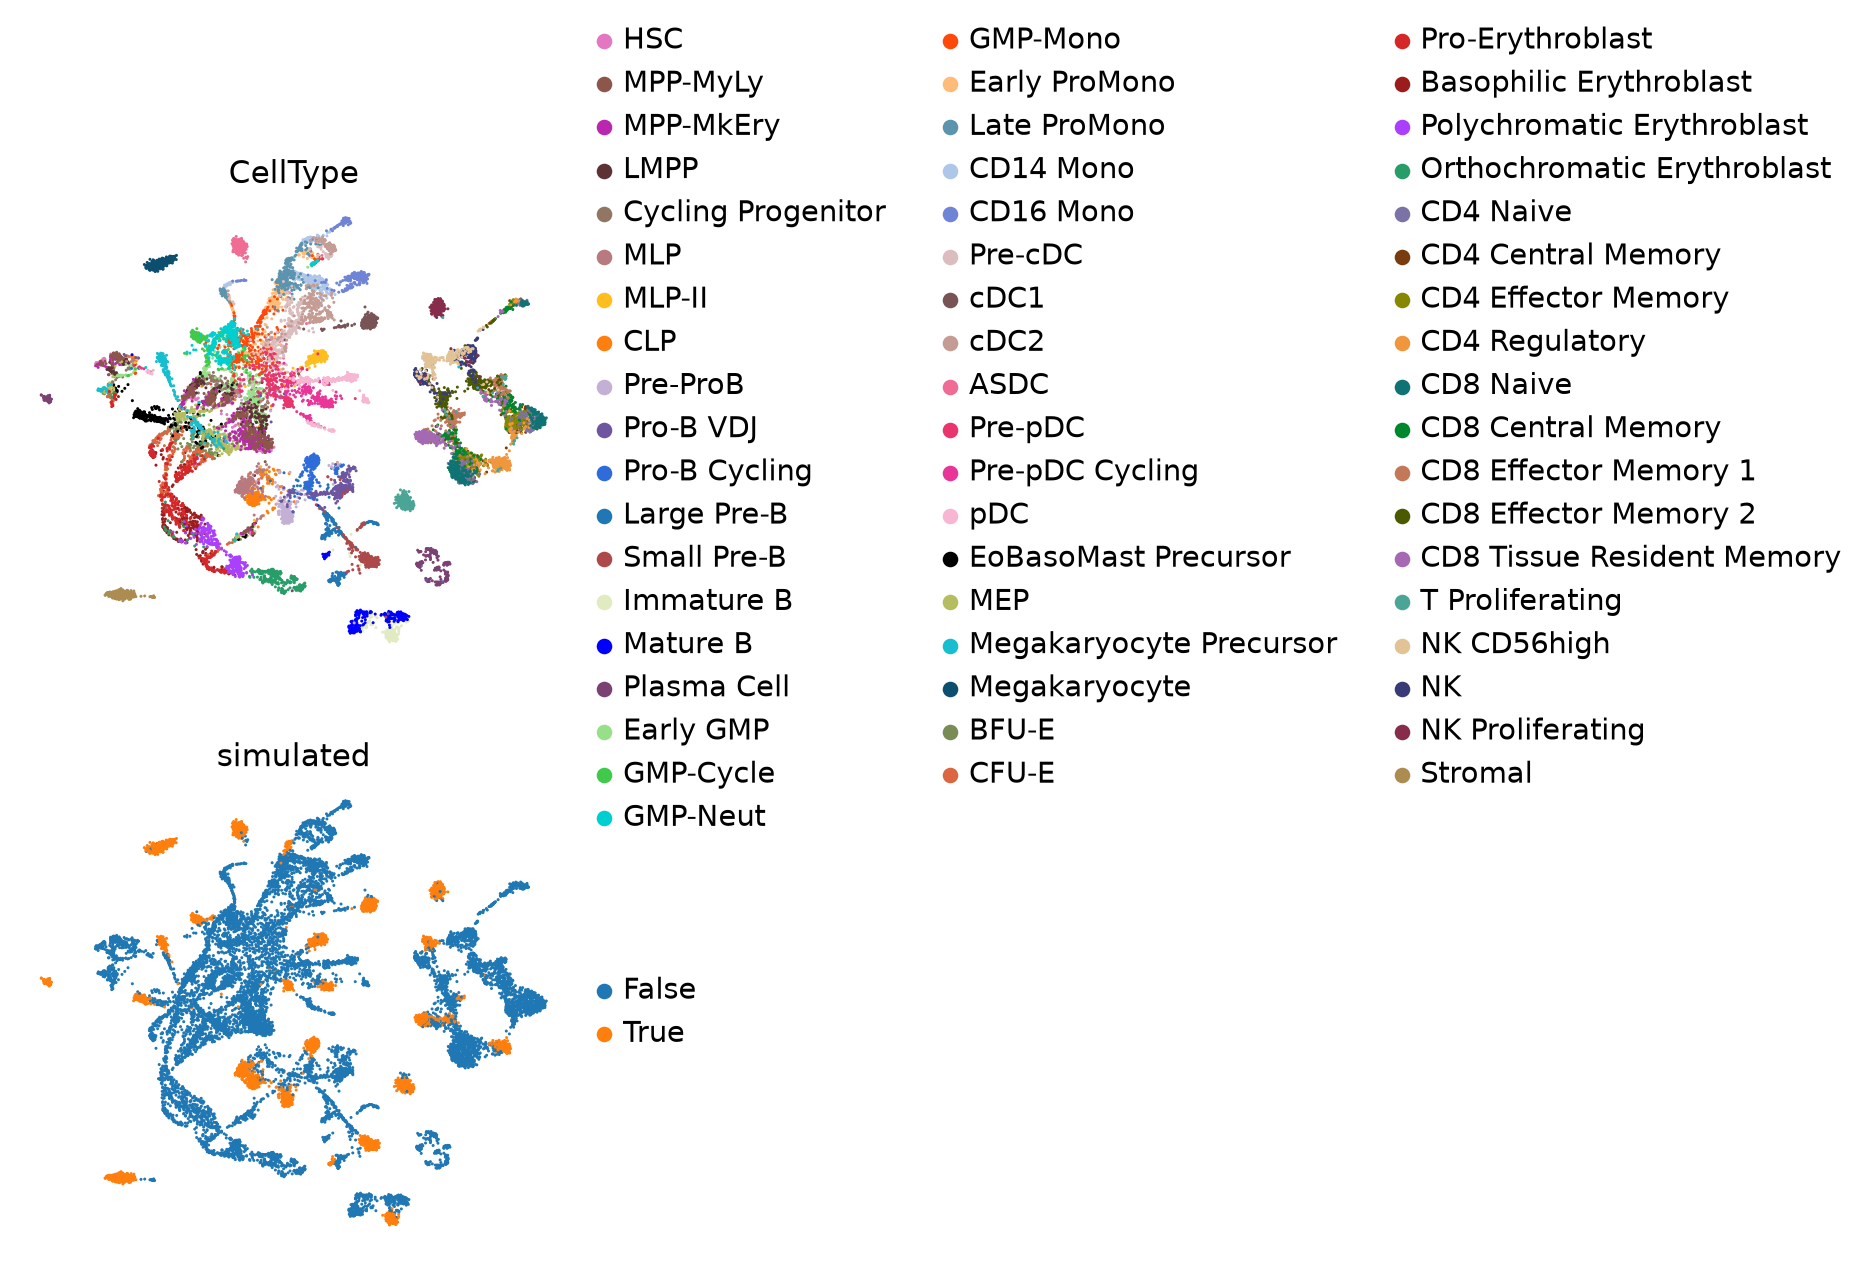

In [4]:
pick = aug.obs.groupby(col, observed=True).sample(300, random_state=0).index
a = aug[pick].copy()
a.obs["simulated"] = a.obs["simulated"].astype(str)
cc.set_colors(a, col)
sc.pp.normalize_total(a, target_sum=1e4)
sc.pp.log1p(a)
sc.pp.highly_variable_genes(a, n_top_genes=3000)
sc.pp.pca(a, n_comps=50, mask_var="highly_variable")
sc.pp.neighbors(a, n_pcs=40)
sc.tl.umap(a)
sc.pl.umap(a, color=[col, "simulated"], ncols=1)

## Does augmentation help the rare types?

Train one model on the real cells only and one on the augmented cells. Both use the genes
that vary in the reference and in the query. Then score both on the held-out real cells.
Recall = share of a type's held-out cells that get the right label. `seed` with
`workers=1` makes training reproducible.

Expect overall accuracy to stay about the same. Mean recall should rise, because the
types with few real cells gain the most. Types that already had many cells change little.

not augmented: accuracy 0.734, mean recall 0.725


augmented: accuracy 0.729, mean recall 0.737
                             not augmented  augmented
CellType                                             
ASDC                                 0.718      0.873
CD4 Regulatory                       0.697      0.749
CD8 Central Memory                   0.409      0.481
CD8 Effector Memory 1                0.751      0.750
CD8 Tissue Resident Memory           0.651      0.725
CLP                                  0.508      0.496
EoBasoMast Precursor                 0.850      0.868
GMP-Cycle                            0.530      0.585
GMP-Neut                             0.812      0.781
Immature B                           0.757      0.843
Large Pre-B                          0.884      0.845
Late ProMono                         0.776      0.763
MLP                                  0.363      0.512
MLP-II                               0.475      0.693
Megakaryocyte                        1.000      1.000
Megakaryocyte Precursor              

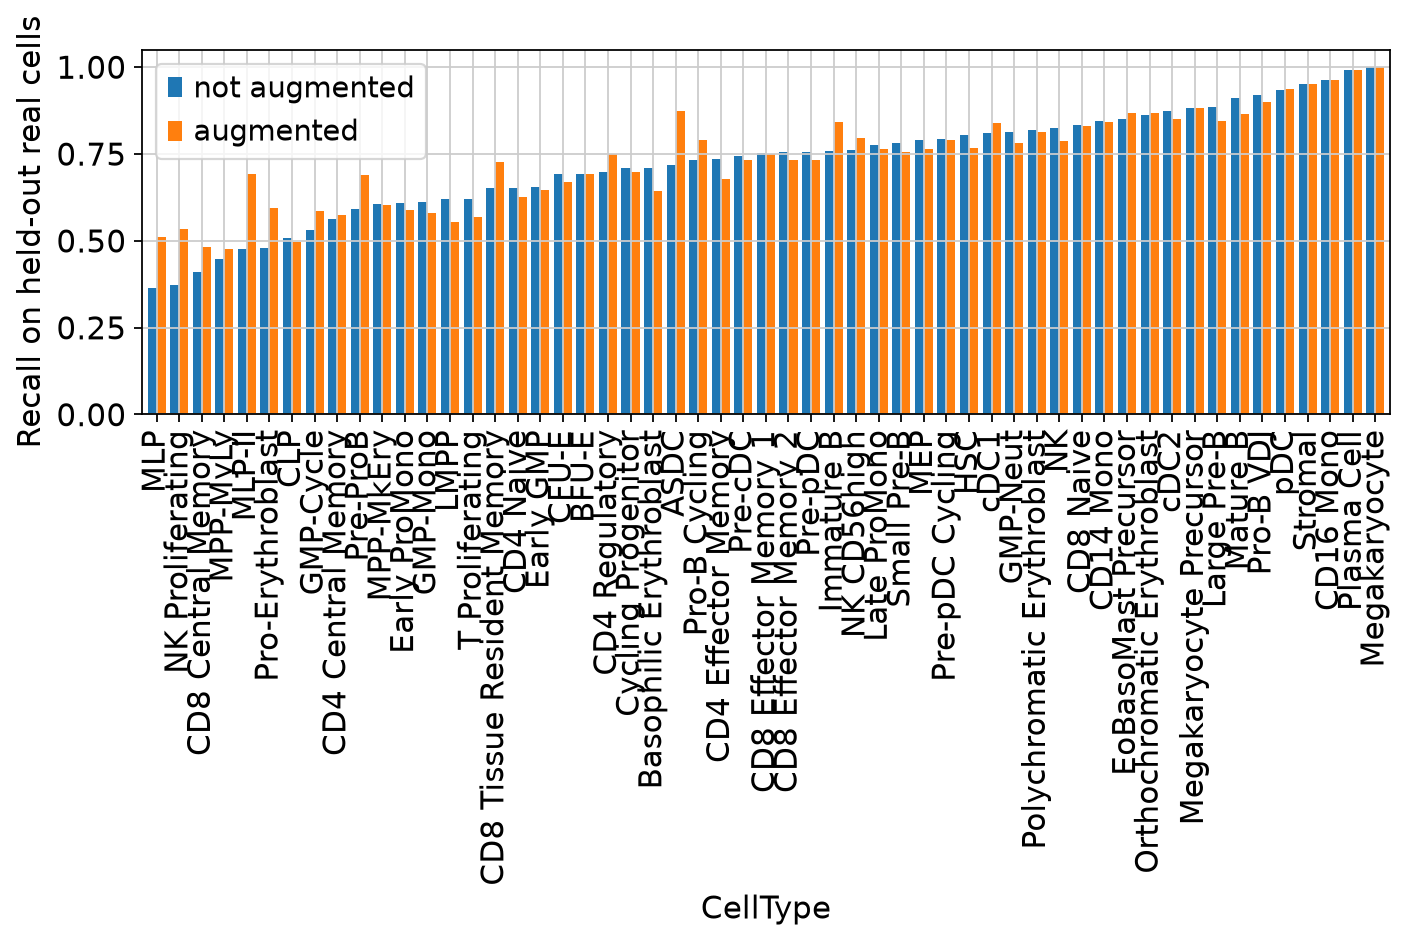

In [5]:
query = td.bm_tcelldep()  # raw counts, the authors' labels and their stored UMAP
vm.calculate_feature_dispersion(query)
vm.select_features(query, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
recall, models = {}, {}
for name, r in (("not augmented", real), ("augmented", aug)):
    vm.calculate_feature_dispersion(r)
    vm.select_features(r, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
    vgr = set(vm.get_selected_features(r))
    vg = [g for g in vm.get_selected_features(query) if g in vgr]
    res = vm.viewmastR(query, r, col, selected_features=vg, query_celldata_col=f"pred_{name}",
                       seed=20261103, workers=1, return_type="list", verbose=False)
    vm.viewmastR_infer(held, res.model_dir, query_celldata_col=f"pred_{name}")
    hit = held.obs[f"pred_{name}"].astype(str) == held.obs[col].astype(str)
    recall[name] = hit.groupby(held.obs[col], observed=True).mean()
    print(f"{name}: accuracy {hit.mean():.3f}, mean recall {recall[name].mean():.3f}")
recall = pd.DataFrame(recall)
print(recall.loc[rare].round(3).to_string())
recall.sort_values("not augmented").plot.bar(figsize=(10, 3), width=0.8)
plt.ylabel("Recall on held-out real cells")
plt.show()

## Label the query with the augmented reference

The query labels came from the augmented model in the loop above. Columns of the
confusion matrix are the authors' labels; rows are the predictions. The two vocabularies
differ, so read it as a mapping. Most author types split into two or more finer
BoneMarrowMap types. For example, author `Mono` cells go to CD14 Mono, Late ProMono and
Early ProMono; author `NaiveB` cells go to Immature B and Mature B. The erythroid
author types follow the maturation order: `EryPre1` to Pro-Erythroblast, `EryPre2` to
Polychromatic Erythroblast, and `Ery` to Orthochromatic Erythroblast.
One mapping is wrong: the 24 author `Mega` cells get EoBasoMast Precursor, not a
megakaryocyte type. Check small types like this one with marker genes.

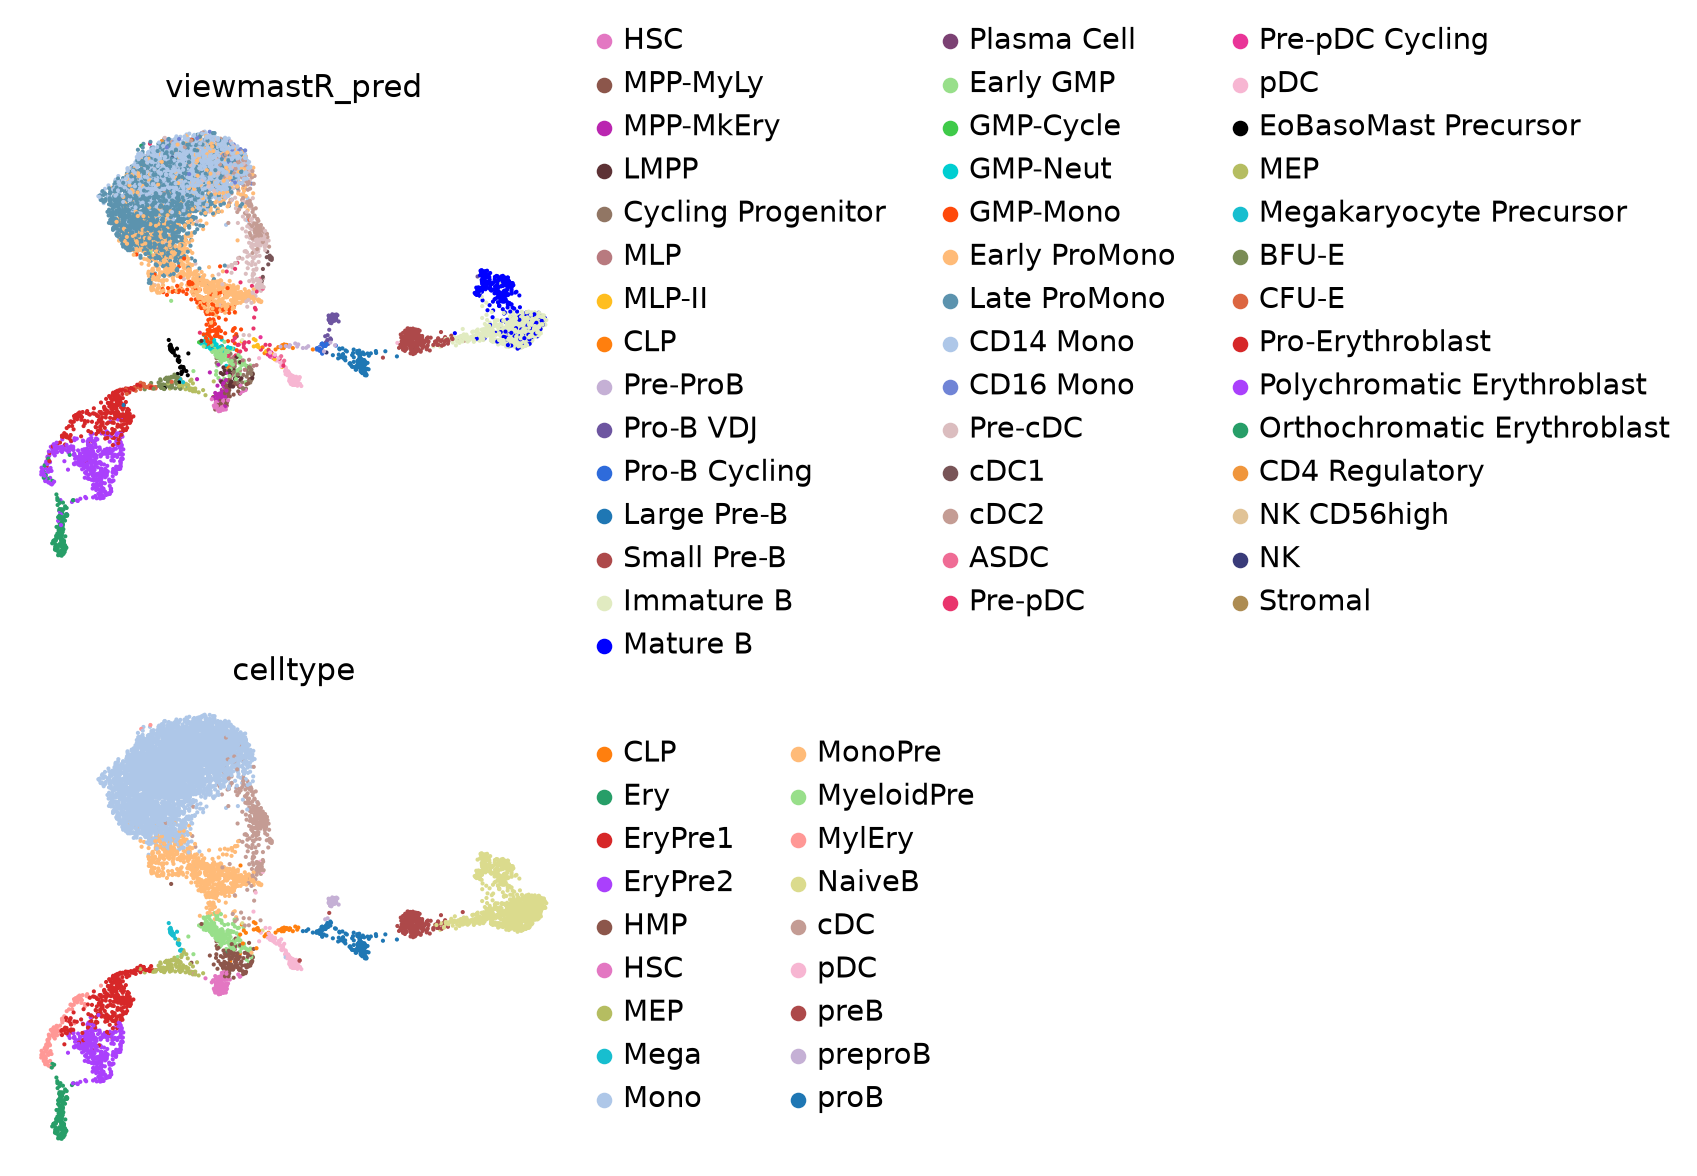

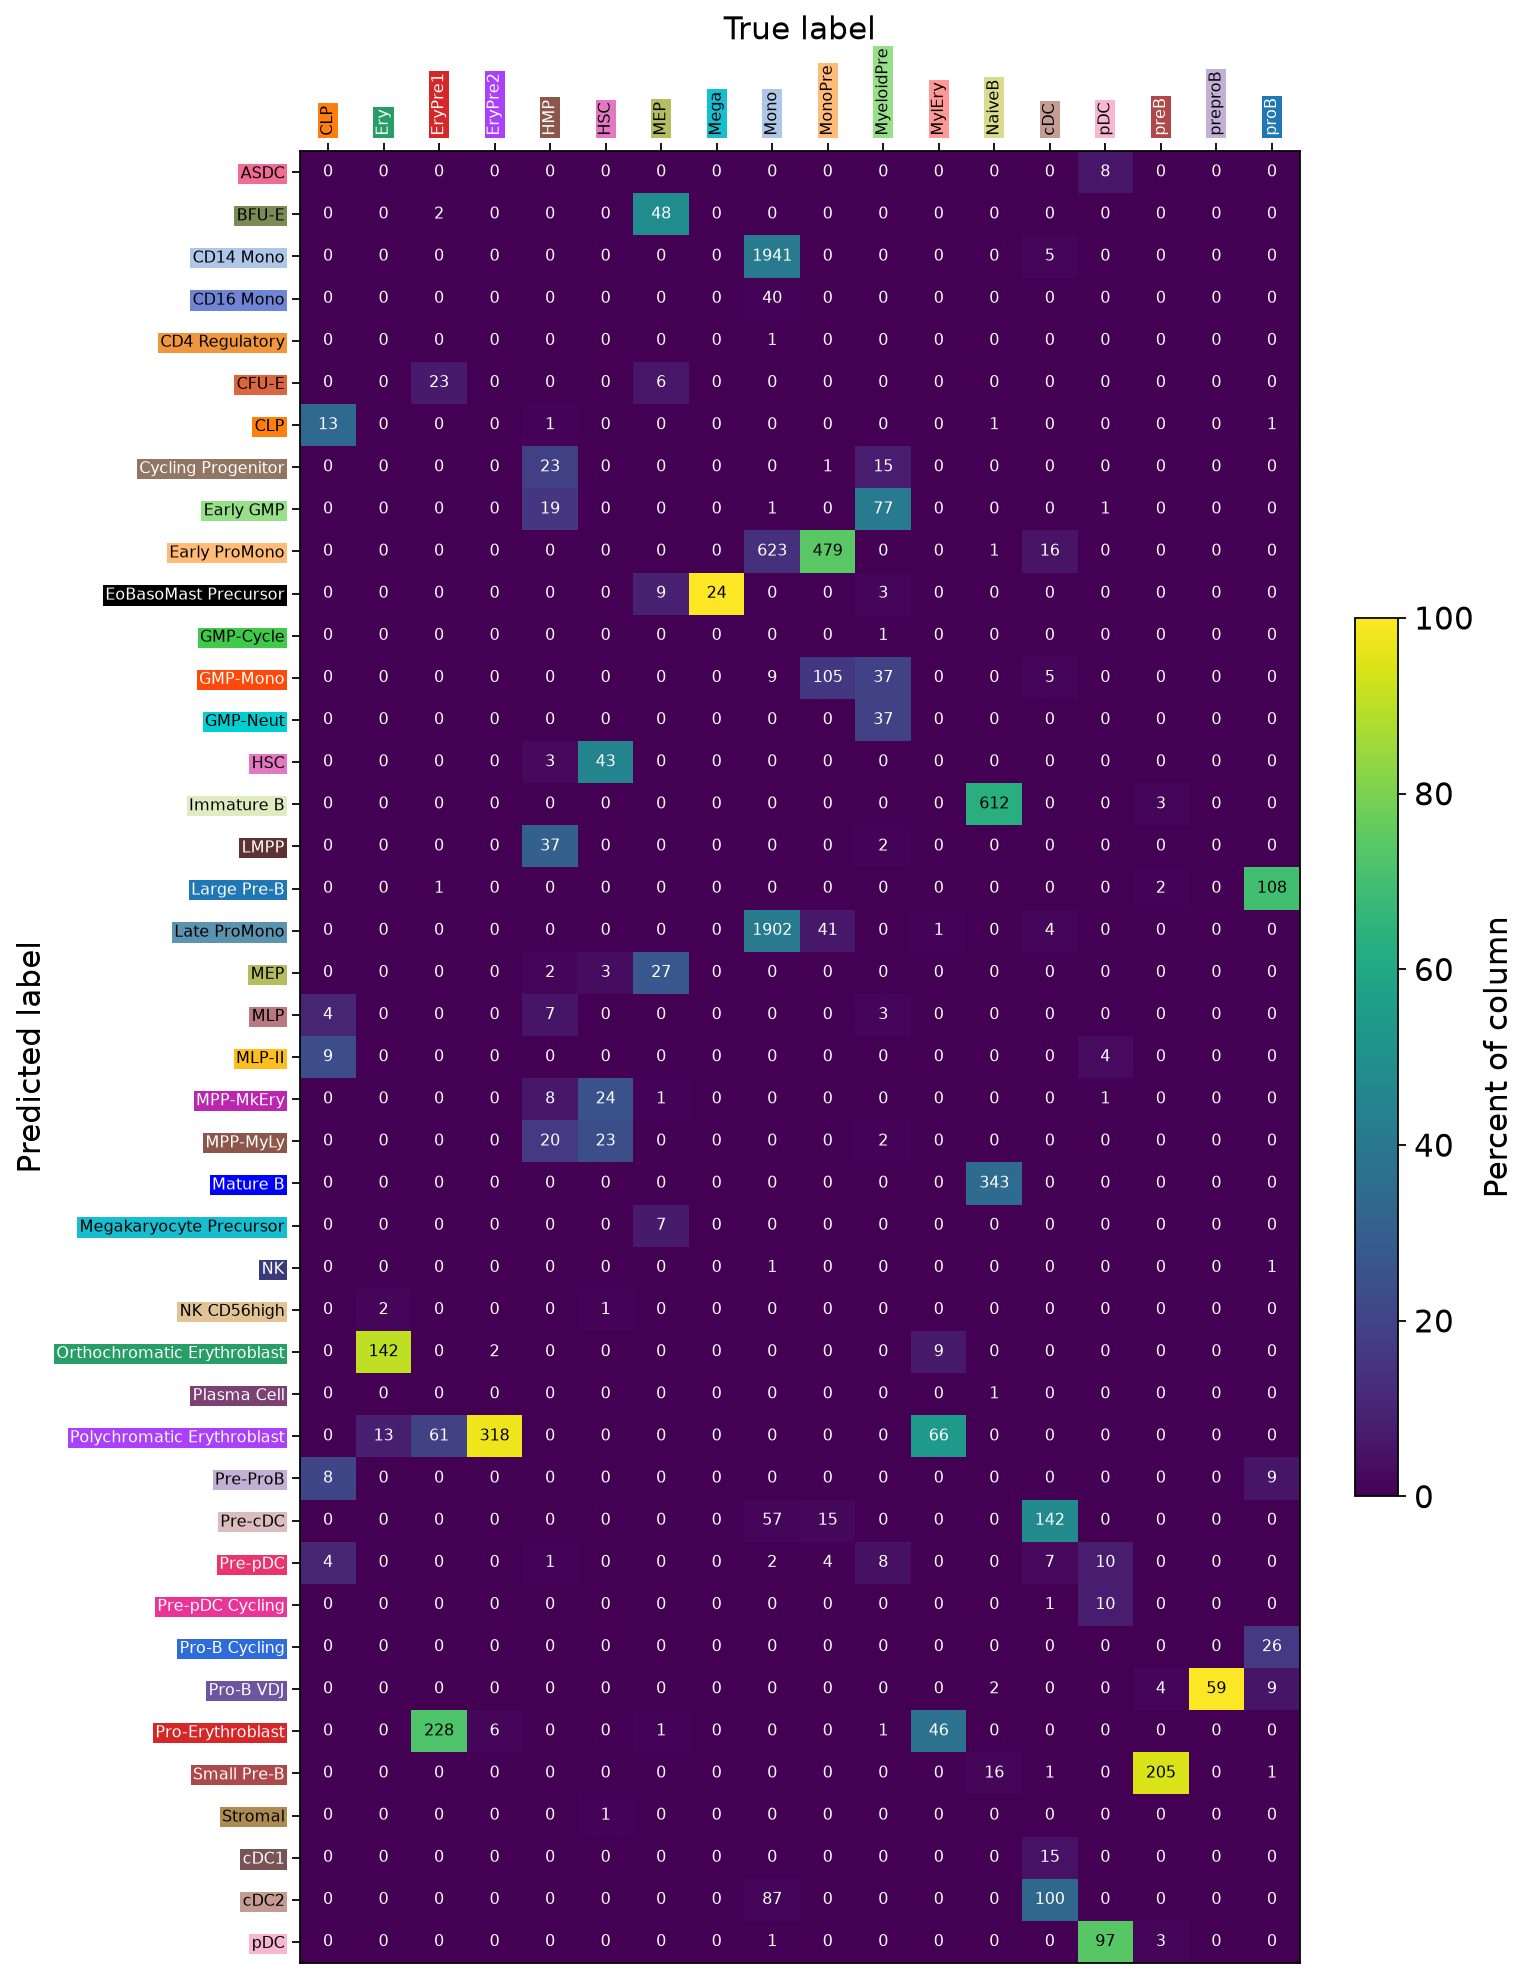

In [6]:
query.obs["viewmastR_pred"] = query.obs["pred_augmented"]
cc.set_colors(query, "viewmastR_pred")
vm.palette.set_colors(query, "celltype")
sc.pl.umap(query, color=["viewmastR_pred", "celltype"], ncols=1)
pred, author = query.obs["viewmastR_pred"], query.obs["celltype"]
vm.confusion_matrix(pred, author, cols={k: cc.color(k) for k in {*pred.astype(str), *author.astype(str)}})
plt.show()

Not translated: the R article first relabels regulatory T cells by cluster and a FOXP3
marker in its own PBMC data. The held-out test above replaces that example.

## Versions

In [7]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
